<a href="https://colab.research.google.com/github/kurhadenarayan44-a11y/Monte_-Carlo_-Portfolio_-Risk_-Simulator/blob/main/Monte__Carlo__Portfolio__Risk__Simulator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Set Seed and Asset Parameters

In [2]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

mean_returns = np.array([0.0004, 0.0006, 0.0003, 0.0005])
volatility = np.array([0.01, 0.015, 0.012, 0.02])

weights = np.array([0.25, 0.25, 0.25, 0.25])

initial_value = 100000
days = 252
simulations = 10000

print("Asset Mean Returns:", mean_returns)
print("Asset Volatility:", volatility)
print("Portfolio Weights:", weights)

Asset Mean Returns: [0.0004 0.0006 0.0003 0.0005]
Asset Volatility: [0.01  0.015 0.012 0.02 ]
Portfolio Weights: [0.25 0.25 0.25 0.25]


# Simulate 10,000 × 252 × 4 Returns

In [4]:
returns = np.random.normal(
    mean_returns,
    volatility,
    (simulations, days, 4)
)

print("Returns Shape:", returns.shape)
print("Number of Simulations:", simulations)
print("Trading Days:", days)
print("Number of Assets:", returns.shape[2])

Returns Shape: (10000, 252, 4)
Number of Simulations: 10000
Trading Days: 252
Number of Assets: 4


# Calculate Portfolio Paths

In [6]:
daily_portfolio_returns = returns @ weights

log_returns = np.log1p(daily_portfolio_returns)

cumulative_returns = np.exp(np.cumsum(log_returns, axis=1))

portfolio_paths = initial_value * cumulative_returns

final_values = portfolio_paths[:, -1]

print("Portfolio Paths Shape:", portfolio_paths.shape)
print("First 10 Final Portfolio Values:")
print(final_values[:10])

Portfolio Paths Shape: (10000, 252)
First 10 Final Portfolio Values:
[111469.89484464 101645.43877022 103399.37914989 121808.02199202
 101158.11642554 129869.02451343 122957.20911949 111668.18153066
 123086.53175616  98783.9956151 ]


# Calculate Volatility and 95% VaR

In [8]:
portfolio_returns = (final_values - initial_value) / initial_value

portfolio_volatility = np.std(portfolio_returns)

losses = initial_value - final_values

var_95 = np.percentile(losses, 95)

average_value = np.mean(final_values)
minimum_value = np.min(final_values)
maximum_value = np.max(final_values)

print("Initial Portfolio Value:", initial_value)
print("Average Final Value:", average_value)
print("Minimum Final Value:", minimum_value)
print("Maximum Final Value:", maximum_value)
print("Annual Portfolio Volatility:", portfolio_volatility * 100, "%")
print("95% Value-at-Risk:", var_95)

Initial Portfolio Value: 100000
Average Final Value: 112094.64187055986
Minimum Final Value: 72968.11657780799
Maximum Final Value: 185186.52275533078
Annual Portfolio Volatility: 13.142434716328264 %
95% Value-at-Risk: 8341.270616141592


# Histogram of Final Portfolio Values

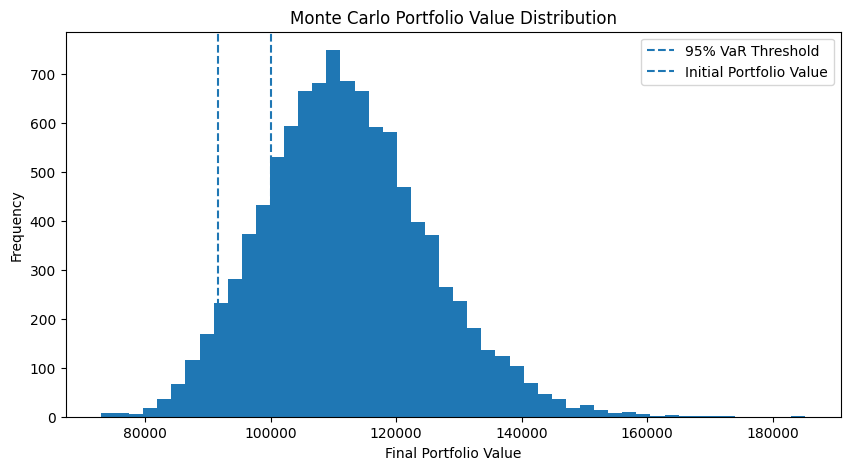

In [9]:
plt.figure(figsize=(10, 5))

plt.hist(final_values, bins=50)

plt.axvline(
    initial_value - var_95,
    linestyle="--",
    label="95% VaR Threshold"
)

plt.axvline(
    initial_value,
    linestyle="--",
    label="Initial Portfolio Value"
)

plt.title("Monte Carlo Portfolio Value Distribution")
plt.xlabel("Final Portfolio Value")
plt.ylabel("Frequency")
plt.legend()
plt.show()

# Display Sample Portfolio Paths

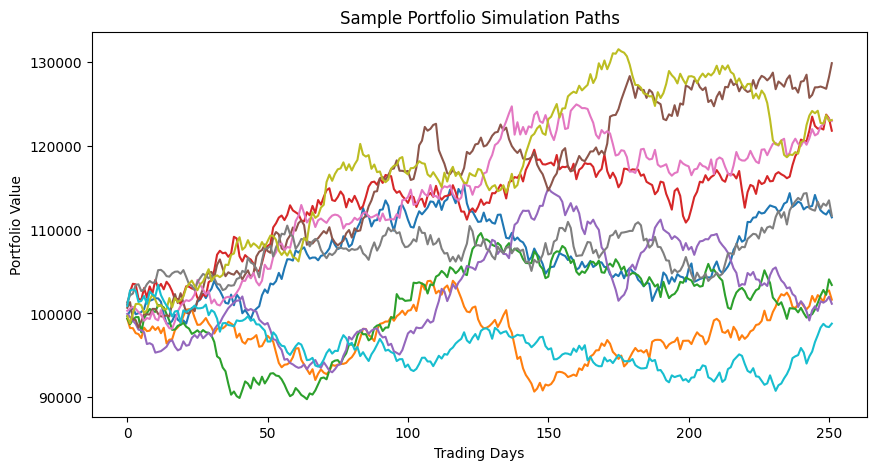

In [10]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.plot(portfolio_paths[i])

plt.title("Sample Portfolio Simulation Paths")
plt.xlabel("Trading Days")
plt.ylabel("Portfolio Value")
plt.show()

# Portfolio Risk Summary

In [11]:
profitable = np.sum(final_values > initial_value)
loss_count = np.sum(final_values < initial_value)

print("Portfolio Risk Summary")
print("Total Simulations:", simulations)
print("Profitable Simulations:", profitable)
print("Loss-Making Simulations:", loss_count)
print("Probability of Profit:", profitable / simulations * 100, "%")
print("Probability of Loss:", loss_count / simulations * 100, "%")
print("95% VaR:", var_95)

Portfolio Risk Summary
Total Simulations: 10000
Profitable Simulations: 8240
Loss-Making Simulations: 1760
Probability of Profit: 82.39999999999999 %
Probability of Loss: 17.599999999999998 %
95% VaR: 8341.270616141592


# Best, Average and Worst Scenarios

In [12]:
best_value = np.max(final_values)
worst_value = np.min(final_values)
average_value = np.mean(final_values)
median_value = np.median(final_values)

print("Best Portfolio Value:", best_value)
print("Average Portfolio Value:", average_value)
print("Median Portfolio Value:", median_value)
print("Worst Portfolio Value:", worst_value)

print("Best Return:", (best_value - initial_value) / initial_value * 100, "%")
print("Average Return:", (average_value - initial_value) / initial_value * 100, "%")
print("Worst Return:", (worst_value - initial_value) / initial_value * 100, "%")

Best Portfolio Value: 185186.52275533078
Average Portfolio Value: 112094.64187055986
Median Portfolio Value: 111242.6120505502
Worst Portfolio Value: 72968.11657780799
Best Return: 85.18652275533077 %
Average Return: 12.094641870559862 %
Worst Return: -27.03188342219201 %


# Smart Risk Alert

In [13]:
if portfolio_volatility < 0.10:
    risk_level = "LOW"
elif portfolio_volatility < 0.20:
    risk_level = "MODERATE"
else:
    risk_level = "HIGH"

print("Portfolio Risk Level:", risk_level)
print("Annual Volatility:", portfolio_volatility * 100, "%")
print("95% VaR:", var_95)

Portfolio Risk Level: MODERATE
Annual Volatility: 13.142434716328264 %
95% VaR: 8341.270616141592


# Compare Two Portfolio Allocations

In [14]:
weights1 = np.array([0.25, 0.25, 0.25, 0.25])
weights2 = np.array([0.40, 0.30, 0.20, 0.10])

returns1 = returns @ weights1
returns2 = returns @ weights2

final1 = initial_value * np.exp(np.sum(np.log1p(returns1), axis=1))
final2 = initial_value * np.exp(np.sum(np.log1p(returns2), axis=1))

risk1 = np.std((final1 - initial_value) / initial_value)
risk2 = np.std((final2 - initial_value) / initial_value)

print("Portfolio 1 Average Value:", np.mean(final1))
print("Portfolio 2 Average Value:", np.mean(final2))
print("Portfolio 1 Volatility:", risk1 * 100, "%")
print("Portfolio 2 Volatility:", risk2 * 100, "%")

Portfolio 1 Average Value: 112094.64187055986
Portfolio 2 Average Value: 112121.9528447874
Portfolio 1 Volatility: 13.14243471632826 %
Portfolio 2 Volatility: 12.14295943838664 %


# Portfolio Risk Comparison Graph

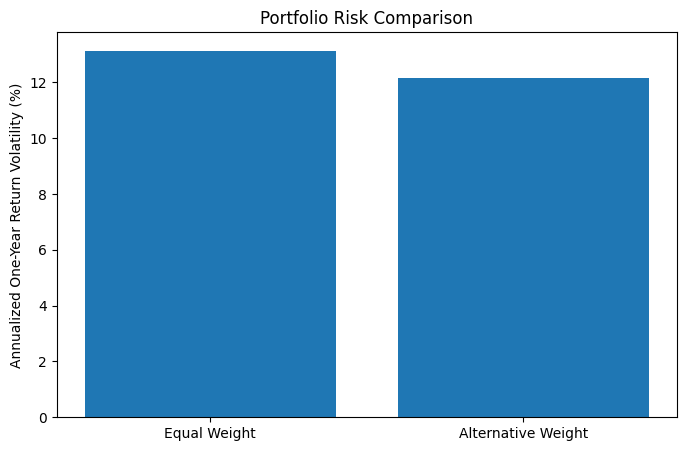

In [15]:
plt.figure(figsize=(8, 5))

plt.bar(
    ["Equal Weight", "Alternative Weight"],
    [risk1 * 100, risk2 * 100]
)

plt.title("Portfolio Risk Comparison")
plt.ylabel("Annualized One-Year Return Volatility (%)")
plt.show()

# Final Dashboard

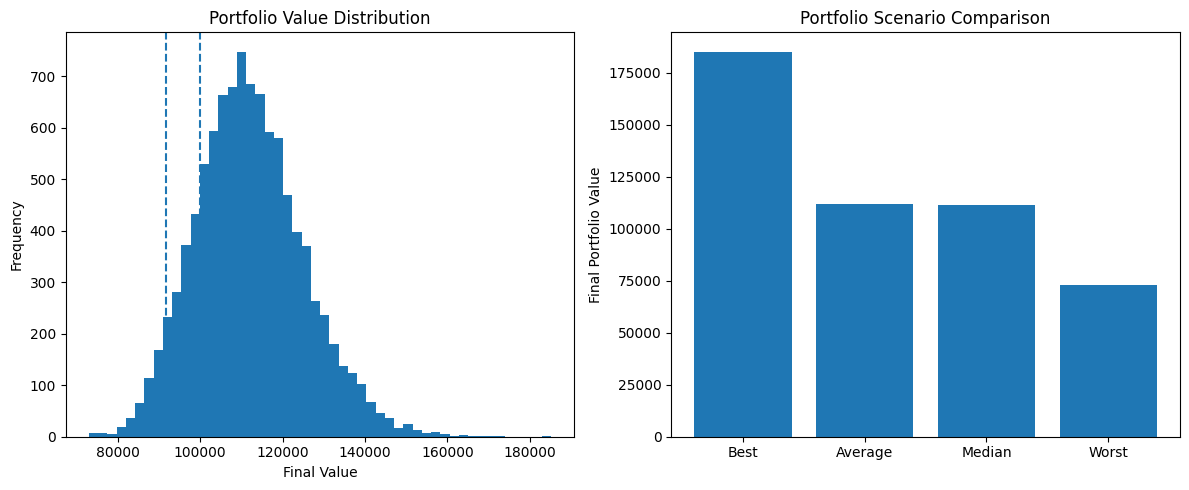

In [16]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(final_values, bins=50)
plt.axvline(initial_value, linestyle="--")
plt.axvline(initial_value - var_95, linestyle="--")
plt.title("Portfolio Value Distribution")
plt.xlabel("Final Value")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.bar(
    ["Best", "Average", "Median", "Worst"],
    [best_value, average_value, median_value, worst_value]
)
plt.title("Portfolio Scenario Comparison")
plt.ylabel("Final Portfolio Value")

plt.tight_layout()
plt.show()

# Simulate Market Crashes

In [18]:
shock_values = [0, -0.05, -0.10]
scenario_names = ["Normal Market", "Moderate Crash", "Severe Crash"]

scenario_values = []
scenario_vars = []
scenario_losses = []

for shock in shock_values:
    new_returns = returns.copy()
    new_returns[:, 125, :] = new_returns[:, 125, :] + shock

    new_portfolio_returns = new_returns @ weights
    new_log_returns = np.log1p(new_portfolio_returns)
    new_paths = initial_value * np.exp(np.sum(new_log_returns, axis=1))

    losses = initial_value - new_paths

    scenario_values.append(np.mean(new_paths))
    scenario_vars.append(np.percentile(losses, 95))
    scenario_losses.append(np.mean(new_paths < initial_value))

print("Market Stress Test")

for i in range(3):
    print(scenario_names[i])
    print("Average Final Value:", scenario_values[i])
    print("95% VaR:", scenario_vars[i])
    print("Probability of Loss:", scenario_losses[i] * 100, "%")

Market Stress Test
Normal Market
Average Final Value: 112094.64187055986
95% VaR: 8341.270616141606
Probability of Loss: 17.599999999999998 %
Moderate Crash
Average Final Value: 106492.93611575745
95% VaR: 12948.2692182666
Probability of Loss: 31.1 %
Severe Crash
Average Final Value: 100891.23036095503
95% VaR: 17528.554040560422
Probability of Loss: 49.480000000000004 %


# Crisis Comparison Graph

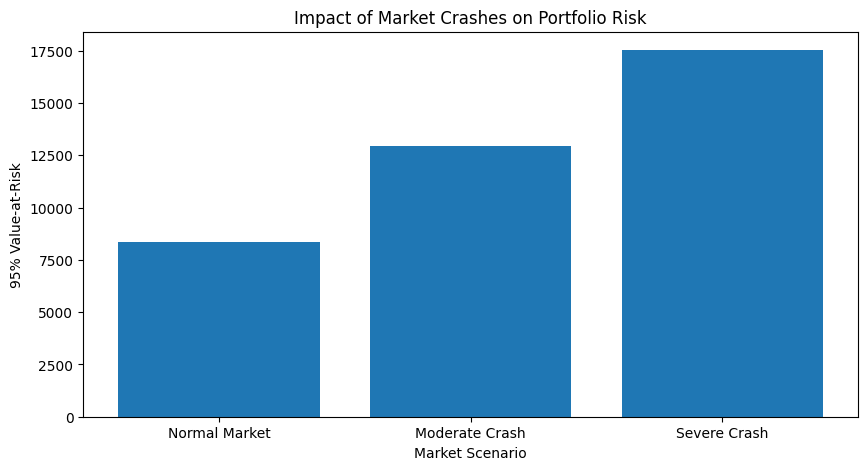

In [19]:
plt.figure(figsize=(10, 5))

plt.bar(scenario_names, scenario_vars)

plt.title("Impact of Market Crashes on Portfolio Risk")
plt.xlabel("Market Scenario")
plt.ylabel("95% Value-at-Risk")
plt.show()

# Risk Impact Dashboard

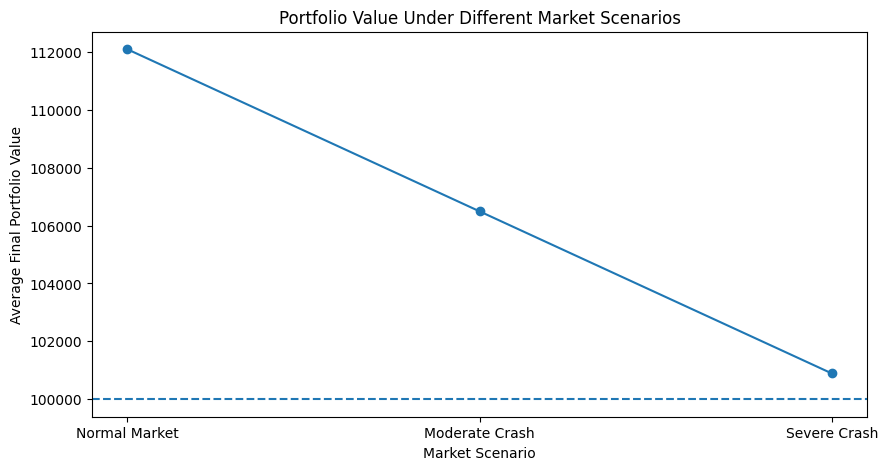

In [20]:
plt.figure(figsize=(10, 5))

plt.plot(scenario_names, scenario_values, marker="o")
plt.axhline(initial_value, linestyle="--")

plt.title("Portfolio Value Under Different Market Scenarios")
plt.xlabel("Market Scenario")
plt.ylabel("Average Final Portfolio Value")
plt.show()

# Automatic Risk Report

In [21]:
for i in range(3):
    print("\nScenario:", scenario_names[i])

    if scenario_vars[i] < 0:
        print("Estimated 95% VaR indicates a net gain threshold.")
    elif scenario_vars[i] < initial_value * 0.10:
        print("Risk Alert: Lower estimated loss exposure.")
    else:
        print("Risk Alert: Higher estimated loss exposure.")

    print("Average Portfolio Value:", scenario_values[i])


Scenario: Normal Market
Risk Alert: Lower estimated loss exposure.
Average Portfolio Value: 112094.64187055986

Scenario: Moderate Crash
Risk Alert: Higher estimated loss exposure.
Average Portfolio Value: 106492.93611575745

Scenario: Severe Crash
Risk Alert: Higher estimated loss exposure.
Average Portfolio Value: 100891.23036095503
